# Notebook 02: Classification Evaluation Metrics Beyond Accuracy

In this notebook, we explore the pitfalls of accuracy and build comprehensive diagnostic tools
for imbalanced classification:

1. **The Imbalanced Accuracy Trap:** Demonstrating how predicting the majority class achieves $98.0\%$ accuracy on a 98:2 fraud detection dataset while finding $0$ fraudsters ($F_1 = 0.0$).
2. **Annotated Confusion Matrix:** Breaking down True Positives (TP), False Positives (FP), False Negatives (FN), and True Negatives (TN).
3. **ROC-AUC vs. PR-AUC:** Why ROC curves look deceptively optimistic when negatives dominate, whereas Precision-Recall curves expose false alarms.
4. **Optimal Decision Thresholding $\tau^*$:** Sweeping $\tau \in [0, 1]$ to maximize $F_1$ and $F_2$ scores.
5. **Reliability Calibration & Brier Score:** Evaluating whether predicted probabilities represent true underlying empirical frequencies.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

REPO_DIR = Path.cwd()
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from src.diagnostics_engine import (
    LogisticRegressionScratch,
    StratifiedKFoldScratch,
    calibration_curve_scratch,
    confusion_matrix_scratch,
    pr_curve_scratch,
    precision_recall_fbeta_scratch,
    roc_curve_scratch,
)
from src.plot_theme import (
    AMBER,
    BG_CANVAS,
    CMAP_SURFACE,
    CORAL,
    CYAN,
    EMERALD,
    PURPLE,
    SLATE_BLUE,
    TEXT_MUTED,
    TEXT_PRIMARY,
    apply_github_dark_style,
    save_fig,
)

apply_github_dark_style()
np.set_printoptions(precision=4, suppress=True)

## 1. 98:2 Severely Imbalanced Fraud Detection Dataset & Stratified 5-Fold CV

We generate $m = 2500$ transactions:
- $2450$ legitimate transactions ($y = 0$, $98\%$)
- $50$ fraudulent transactions ($y = 1$, $2\%$)

Using `StratifiedKFoldScratch`, every fold contains exactly $10$ fraudulent cases.
We collect out-of-fold probability predictions $\hat{p}^{(i)}$ for all $2500$ samples.

In [2]:
rng = np.random.default_rng(2026)
m_total = 2500
m_pos = 50
m_neg = m_total - m_pos

X_neg = rng.normal(loc=0.0, scale=1.0, size=(m_neg, 6))
X_pos = rng.normal(loc=[1.45, -1.35, 1.15, 0.85, -0.6, 0.3], scale=1.05, size=(m_pos, 6))
X_imb = np.vstack([X_neg, X_pos])
y_imb = np.concatenate([np.zeros(m_neg, dtype=np.int64), np.ones(m_pos, dtype=np.int64)])

# 5-Fold Stratified Cross-Validation
skf = StratifiedKFoldScratch(n_splits=5, shuffle=True, random_state=42)
oof_probs = np.zeros(m_total, dtype=np.float64)

for fold_idx, (tr_idx, val_idx) in enumerate(skf.split(X_imb, y_imb)):
    clf = LogisticRegressionScratch(learning_rate=0.3, epochs=700)
    clf.fit(X_imb[tr_idx], y_imb[tr_idx])
    oof_probs[val_idx] = clf.predict_proba(X_imb[val_idx])

# Evaluate policy comparisons
tau_candidates = np.linspace(0.02, 0.90, 180)
f1_scores = [precision_recall_fbeta_scratch(y_imb, (oof_probs >= t).astype(int), beta=1.0)["f_beta"] for t in tau_candidates]
f2_scores = [precision_recall_fbeta_scratch(y_imb, (oof_probs >= t).astype(int), beta=2.0)["f_beta"] for t in tau_candidates]
best_tau = float(tau_candidates[int(np.argmax(f1_scores))])

dummy_stats = precision_recall_fbeta_scratch(y_imb, np.zeros_like(y_imb))
default_stats = precision_recall_fbeta_scratch(y_imb, (oof_probs >= 0.50).astype(int))
optimal_stats = precision_recall_fbeta_scratch(y_imb, (oof_probs >= best_tau).astype(int))

print(f"{'Classifier Policy':<34} | {'Accuracy':<9} | {'Precision':<9} | {'Recall':<9} | {'F1-Score':<9}")
print("-" * 80)
for name, st in [
    ("Dummy Always-0 Classifier", dummy_stats),
    ("Logistic Default (tau = 0.50)", default_stats),
    (f"Logistic F1-Optimal (tau* = {best_tau:.3f})", optimal_stats),
]:
    print(f"{name:<34} | {st['accuracy']*100:7.2f}%  | {st['precision']*100:7.2f}%  | {st['recall']*100:7.2f}%  | {st['f_beta']:8.4f}")

Classifier Policy                  | Accuracy  | Precision | Recall    | F1-Score 
--------------------------------------------------------------------------------
Dummy Always-0 Classifier          |   98.00%  |    0.00%  |    0.00%  |   0.0000
Logistic Default (tau = 0.50)      |   98.48%  |   75.00%  |   36.00%  |   0.4865
Logistic F1-Optimal (tau* = 0.281) |   98.60%  |   68.29%  |   56.00%  |   0.6154


## 2. Four-Panel Evaluation Dashboard (`02_roc_pr_calibration_dashboard.png`)

- **Panel A (Annotated Confusion Matrix):** Displays TN, FP (Type I error), FN (Type II error), and TP at threshold $\tau^*$.
- **Panel B (Receiver Operating Characteristic):** Plots TPR vs. FPR across all thresholds. Displays ROC-AUC.
- **Panel C (Precision–Recall Curve):** Shows Precision vs. Recall alongside $F_1(\tau)$ and $F_2(\tau)$ threshold sweeps.
- **Panel D (Reliability Calibration Diagram):** Compares our calibrated model against an uncalibrated overconfident scorer, computing Brier scores.

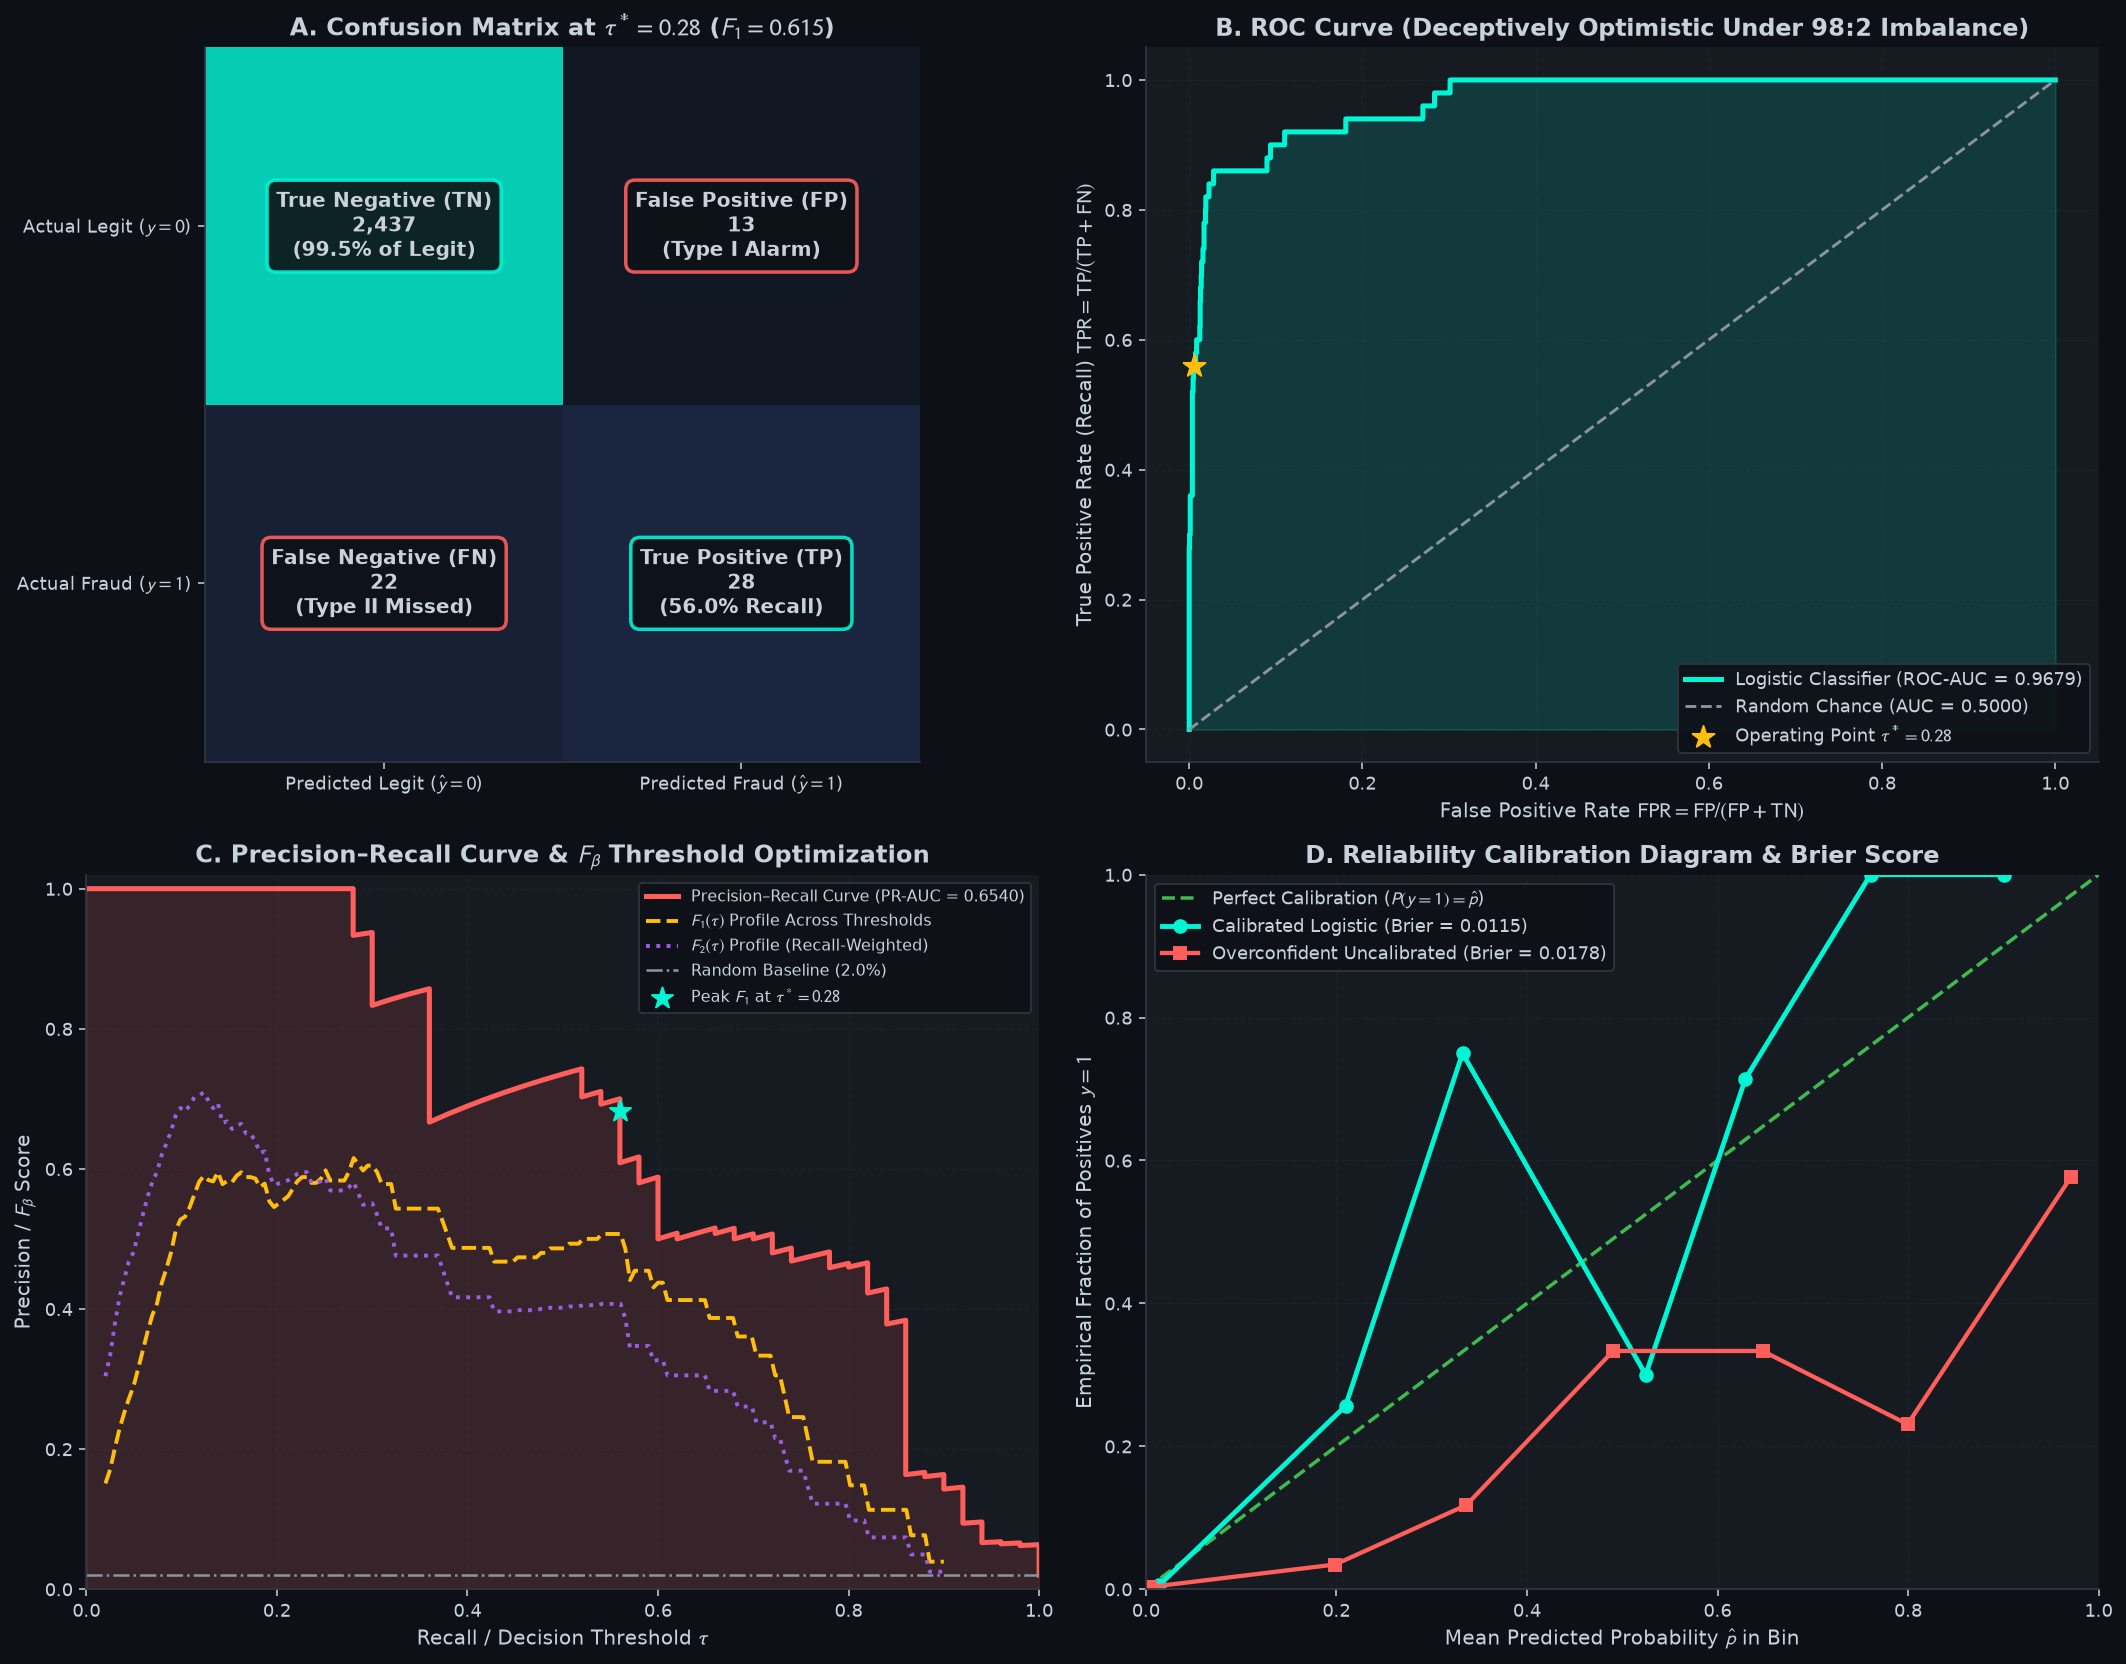

In [3]:
fpr_arr, tpr_arr, _, roc_auc = roc_curve_scratch(y_imb, oof_probs)
rec_arr, prec_arr, _, pr_auc = pr_curve_scratch(y_imb, oof_probs)

overconf_probs = 1.0 / (1.0 + np.exp(-3.2 * (np.log(np.clip(oof_probs, 1e-9, 1 - 1e-9) / (1.0 - np.clip(oof_probs, 1e-9, 1 - 1e-9))) + 1.8)))
cal_pred_log, cal_true_log, brier_log = calibration_curve_scratch(y_imb, oof_probs, n_bins=7)
cal_pred_ovc, cal_true_ovc, brier_ovc = calibration_curve_scratch(y_imb, overconf_probs, n_bins=7)

tn, fp, fn, tp = confusion_matrix_scratch(y_imb, (oof_probs >= best_tau).astype(int))
cm_mat = np.array([[tn, fp], [fn, tp]], dtype=np.float64)

fig, axes = plt.subplots(2, 2, figsize=(15.5, 12.0))

# Panel A: Confusion Matrix
ax1 = axes[0, 0]
im = ax1.imshow(np.log1p(cm_mat), cmap=CMAP_SURFACE, alpha=0.82)
ax1.grid(False)
cell_labels = [
    [f"True Negative (TN)\n{tn:,}\n({tn/m_neg*100:.1f}% of Legit)", f"False Positive (FP)\n{fp:,}\n(Type I Alarm)"],
    [f"False Negative (FN)\n{fn:,}\n(Type II Missed)", f"True Positive (TP)\n{tp:,}\n({tp/m_pos*100:.1f}% Recall)"],
]
for r in range(2):
    for c in range(2):
        box_col = CYAN if r == c else CORAL
        ax1.text(
            c, r, cell_labels[r][c],
            ha="center", va="center",
            color=TEXT_PRIMARY,
            fontweight="bold",
            fontsize=10.5,
            bbox=dict(boxstyle="round,pad=0.45", facecolor=BG_CANVAS, edgecolor=box_col, linewidth=1.8, alpha=0.9),
        )
ax1.set_xticks([0, 1])
ax1.set_yticks([0, 1])
ax1.set_xticklabels([r"Predicted Legit ($\hat{y}=0$)", r"Predicted Fraud ($\hat{y}=1$)"])
ax1.set_yticklabels(["Actual Legit ($y=0$)", "Actual Fraud ($y=1$)"])
ax1.set_title(rf"A. Confusion Matrix at $\tau^* = {best_tau:.2f}$ ($F_1 = {optimal_stats['f_beta']:.3f}$)")

# Panel B: ROC Curve
ax2 = axes[0, 1]
ax2.plot(fpr_arr, tpr_arr, color=CYAN, linewidth=2.6, label=f"Logistic Classifier (ROC-AUC = {roc_auc:.4f})")
ax2.fill_between(fpr_arr, 0, tpr_arr, color=CYAN, alpha=0.14)
ax2.plot([0, 1], [0, 1], color=TEXT_MUTED, linestyle="--", linewidth=1.5, label="Random Chance (AUC = 0.5000)")
ax2.scatter([optimal_stats["fpr"]], [optimal_stats["recall"]], color=AMBER, s=140, marker="*", zorder=6, label=rf"Operating Point $\tau^*={best_tau:.2f}$")
ax2.set_xlabel(r"False Positive Rate $\mathrm{FPR} = \mathrm{FP} / (\mathrm{FP} + \mathrm{TN})$")
ax2.set_ylabel(r"True Positive Rate (Recall) $\mathrm{TPR} = \mathrm{TP} / (\mathrm{TP} + \mathrm{FN})$")
ax2.set_title("B. ROC Curve (Deceptively Optimistic Under 98:2 Imbalance)")
ax2.legend(loc="lower right")

# Panel C: PR Curve
ax3 = axes[1, 0]
ax3.plot(rec_arr, prec_arr, color=CORAL, linewidth=2.6, label=f"Precision–Recall Curve (PR-AUC = {pr_auc:.4f})")
ax3.fill_between(rec_arr, 0, prec_arr, color=CORAL, alpha=0.14)
ax3.plot(tau_candidates, f1_scores, color=AMBER, linestyle="--", linewidth=2.0, label=r"$F_1(\tau)$ Profile Across Thresholds")
ax3.plot(tau_candidates, f2_scores, color=PURPLE, linestyle=":", linewidth=2.0, label=r"$F_2(\tau)$ Profile (Recall-Weighted)")
ax3.axhline(m_pos / m_total, color=TEXT_MUTED, linestyle="-.", linewidth=1.3, label=f"Random Baseline ({m_pos/m_total*100:.1f}%)")
ax3.scatter([optimal_stats["recall"]], [optimal_stats["precision"]], color=CYAN, s=130, marker="*", zorder=7, label=rf"Peak $F_1$ at $\tau^*={best_tau:.2f}$")
ax3.set_xlim(0.0, 1.0)
ax3.set_ylim(0.0, 1.02)
ax3.set_xlabel(r"Recall / Decision Threshold $\tau$")
ax3.set_ylabel(r"Precision / $F_\beta$ Score")
ax3.set_title(r"C. Precision–Recall Curve & $F_\beta$ Threshold Optimization")
ax3.legend(loc="upper right", fontsize=8.3)

# Panel D: Reliability Calibration
ax4 = axes[1, 1]
ax4.plot([0, 1], [0, 1], color=EMERALD, linestyle="--", linewidth=1.8, label=r"Perfect Calibration ($P(y=1)=\hat{p}$)")
ax4.plot(cal_pred_log, cal_true_log, color=CYAN, marker="o", linewidth=2.5, markersize=6.5, label=f"Calibrated Logistic (Brier = {brier_log:.4f})")
ax4.plot(cal_pred_ovc, cal_true_ovc, color=CORAL, marker="s", linewidth=2.2, markersize=6.0, label=f"Overconfident Uncalibrated (Brier = {brier_ovc:.4f})")
ax4.set_xlim(0.0, 1.0)
ax4.set_ylim(0.0, 1.0)
ax4.set_xlabel(r"Mean Predicted Probability $\hat{p}$ in Bin")
ax4.set_ylabel(r"Empirical Fraction of Positives $y=1$")
ax4.set_title("D. Reliability Calibration Diagram & Brier Score")
ax4.legend(loc="upper left")

fig.tight_layout()
save_fig(fig, REPO_DIR / "assets" / "02_roc_pr_calibration_dashboard.png")
plt.show()